# 1. Análise exploratória dos preços da cesta básica

## 1.1 Introdução e questão de pesquisa
É possível antecipar uma alta **superior a 2% no mês seguinte**, para um produto e supermercado, usando preços históricos? Esta etapa descreve dados e qualidade; não estima desempenho preditivo.

## 2. Descrição e leitura da fonte
O repositório contém uma planilha XLSX, não o CSV originalmente esperado. A aba disponível é lida diretamente, sem alterar a fonte. `Mes_Ano_Data` é o mês de referência; `Data_Coleta` pode estar ausente e não é inventada.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from basket_price_prediction.config import ROOT, DATASET, SPLITS, FEATURES, ENTITY
from basket_price_prediction.data import load_data
from basket_price_prediction.preprocessing import diagnose_suspicious_prices, prepare_monthly
from basket_price_prediction.features import build_supervised, temporal_split
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
raw = load_data()
display(raw.head(10))
print("Dimensões:", raw.shape)
display(pd.DataFrame({"tipo":raw.dtypes.astype(str), "ausentes":raw.isna().sum(), "distintos":raw.nunique()}))

,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1.0,54.20
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
2,2022-09-01,2022-09-21,SUP_09,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
3,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1.0,51.99
4,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1.0,51.90
5,2022-09-01,2022-09-26,SUP_13,Carne Bovina Coxão Mole,NaN,50.49,1.0,50.49
6,2022-09-01,2022-09-23,SUP_34,Carne Bovina Coxão Mole,NaN,48.99,1.0,48.99
7,2022-09-01,2022-09-21,SUP_08,Carne Bovina Coxão Mole,NaN,48.90,1.0,48.90
8,2022-09-01,2022-09-23,SUP_36,Carne Bovina Coxão Mole,NaN,47.99,1.0,47.99
9,2022-09-01,2022-09-23,SUP_50,Carne Bovina Coxão Mole,NaN,46.90,1.0,46.90


Dimensões: (46264, 8)


,tipo,ausentes,distintos
Mes_Ano_Data,datetime64[ns],0,48
Data_Coleta,datetime64[ns],9818,304
Estab,object,0,51
Produto,object,0,30
Marca,object,9346,170
Preco,float64,0,1613
Quantidade,float64,0,19
PPK,float64,0,2817


## 3. Cobertura e integridade
Inspecione observações repetidas, datas ausentes, valores inválidos e possíveis divergências entre mês de coleta e referência. Contagens de motivos podem se sobrepor.

In [2]:
monthly, cleaning = prepare_monthly(raw)
print("Período:", raw.Mes_Ano_Data.min(), "a", raw.Mes_Ano_Data.max())
display(pd.Series(cleaning, name="valor").to_frame())
display(raw[["Produto", "Marca", "Quantidade"]].nunique().to_frame("valores distintos"))
display(raw.groupby("Produto").agg(registros=("Preco","size"), marcas=("Marca","nunique"), quantidades=("Quantidade","nunique")).sort_values("registros",ascending=False))

Período: 2022-09-01 00:00:00 a 2026-08-01 00:00:00


,valor
initial_records,46264
missing_by_column,"{'Mes_Ano_Data': 0, 'Data_Coleta': 9818, 'Esta..."
exact_duplicates,1743
invalid_reasons_overlapping,"{'month': 0, 'entity': 0, 'price': 0, 'quantit..."
valid_records_after_deduplication,44521
ppk_discrepancies_over_0_01,0
monthly_observations,43948
monthly_series,4216
aggregated_extra_records,573
missing_brand_label,(não informada)


,valores distintos
Produto,30
Marca,170
Quantidade,19


,registros,marcas,quantidades
Produto,,,
Café,5378,15,3
Arroz,5305,32,3
Manteiga,4875,44,8
Feijão,4790,40,2
Leite,4651,25,1
Farinha de Trigo,4196,25,3
Óleo,3165,15,2
Açúcar,3101,18,4
Tomate,1332,1,2


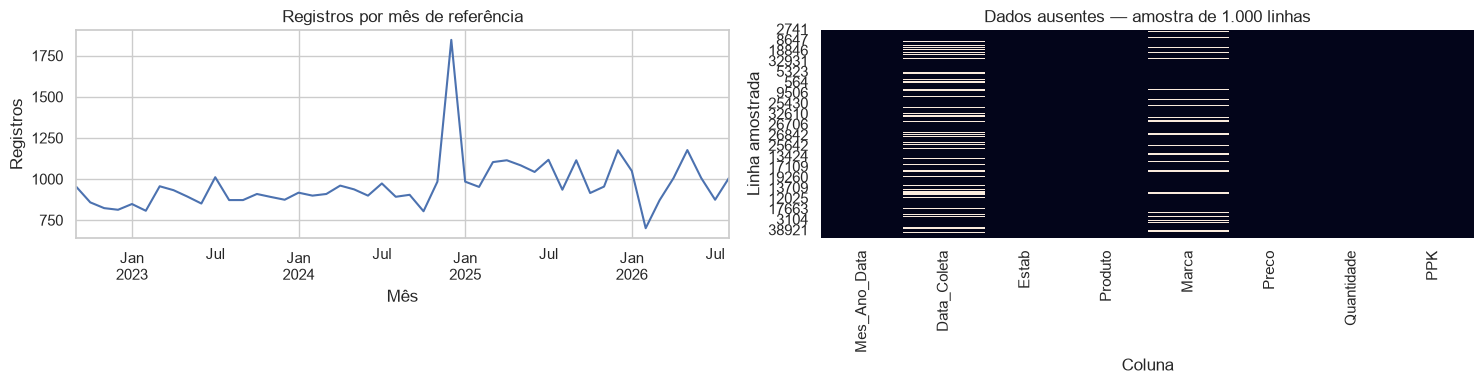

,registros,marcas_ausentes,datas_de_coleta_ausentes
Mes_Ano_Data,,,
2022-09-01,952,136,0
2022-10-01,858,132,0
2022-11-01,823,127,0
2022-12-01,813,131,0
2023-01-01,848,127,0
2023-02-01,807,125,0
2023-03-01,956,158,0
2023-04-01,932,183,0
2023-05-01,893,154,0


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15,4))
raw.groupby("Mes_Ano_Data").size().plot(ax=axes[0]); axes[0].set(title="Registros por mês de referência", xlabel="Mês", ylabel="Registros")
sns.heatmap(raw.isna().sample(min(1000,len(raw)),random_state=42), cbar=False, ax=axes[1]); axes[1].set(title="Dados ausentes — amostra de 1.000 linhas", xlabel="Coluna", ylabel="Linha amostrada")
plt.tight_layout(); plt.show()

coverage_by_month = raw.assign(
    marca_ausente=raw.Marca.fillna("").str.strip().eq(""),
    coleta_ausente=raw.Data_Coleta.isna(),
).groupby("Mes_Ano_Data").agg(
    registros=("Preco", "size"),
    marcas_ausentes=("marca_ausente", "sum"),
    datas_de_coleta_ausentes=("coleta_ausente", "sum"),
)
display(coverage_by_month)


## 4. Padronização e definição de série
`PPK` é comparado com preço dividido por quantidade; a unidade física de cada produto não está documentada. Portanto não se afirma que seja R$/kg. A variável escolhida é o preço da embalagem original, mantida constante por supermercado, produto, marca e quantidade. Marca ausente é uma categoria explícita, sujeita a misturar marcas desconhecidas. Duplicatas exatas são removidas e registros distintos do mesmo mês usam mediana. Nenhum extremo é removido automaticamente.

In [4]:
display(raw.groupby("Produto").agg(quantidades=("Quantidade",lambda x: sorted(x.unique().tolist())), marcas=("Marca","nunique")).head(30))
print("Divergências PPK vs preço/quantidade > R$ 0,01:",cleaning["ppk_discrepancies_over_0_01"])
print("Duplicatas exatas:",cleaning["exact_duplicates"],"; registros agregados além do primeiro:",cleaning["aggregated_extra_records"])
print("Descrições originais:", sorted(raw.Produto.dropna().unique()))

,quantidades,marcas
Produto,,
Arroz,"[1.0, 2.0, 5.0]",32
Açúcar,"[0.5, 1.0, 2.0, 3.0]",18
Banana Nanica,"[0.7, 1.0]",1
Banana Prata,[1.0],1
Batata,[1.0],1
Café,"[0.25, 0.5, 1.0]",15
Carne Acem,[1.0],0
Carne Bovina Acem,[1.0],0
Carne Bovina Alcatra,[1.0],0


Divergências PPK vs preço/quantidade > R$ 0,01: 0
Duplicatas exatas: 1743 ; registros agregados além do primeiro: 573
Descrições originais: ['Arroz', 'Açúcar', 'Banana Nanica', 'Banana Prata', 'Batata', 'Café', 'Carne Acem', 'Carne Bovina Acem', 'Carne Bovina Alcatra', 'Carne Bovina Coxão Mole', 'Carne Bovina Músculo', 'Carne Bovina Patinho', 'Carne Coxão Mole', 'Carne Pernil', 'Carne Suína Pernil', 'Farinha', 'Farinha de Trigo', 'Feijão', 'Frango Peito', 'Frango Sobrecoxa', 'Leite', 'Macarrão', 'Macarrão com Ovos', 'Manteiga', 'Ovo', 'Pernil', 'Pão', 'Pão Francês', 'Tomate', 'Óleo']


### Triagem de preços suspeitos
O diagnóstico compara cada preço coletado com a mediana entre os meses imediatamente anterior e posterior da mesma série, usando os meses disponíveis. Também compara com a mediana de pelo menos dois outros supermercados no mesmo mês, para produto, marca e quantidade iguais. Um preço é sinalizado se atingir pelo menos três vezes ou no máximo um terço de alguma referência. Marca ausente limita a comparabilidade. Os preços sinalizados permanecem na agregação e no treinamento.

In [5]:
flags = diagnose_suspicious_prices(raw)
print(f"{len(flags)} registros sinalizados entre {cleaning['valid_records_after_deduplication']} registros válidos após deduplicação.")
columns = [*ENTITY, "month", "price", "previous_month_median", "next_month_median",
           "peer_stores", "peer_median", "reason"]
display(flags[columns].head(15))
named_cases = ((flags["product"].str.contains("banana", case=False) & flags.price.eq(999)) |
               (flags["product"].str.contains("sobrecoxa", case=False) & flags.price.eq(0.10)))
display(flags.loc[named_cases, columns])

52 registros sinalizados entre 44521 registros válidos após deduplicação.


,supermarket,product,brand,quantity,month,price,previous_month_median,next_month_median,peer_stores,peer_median,reason
0,SUP_17,Carne Bovina Coxão Mole,(não informada),1.0,2025-11-01,0.10,46.490,NaN,23,49.890,Meses vizinhos e outros mercados
1,SUP_17,Carne Bovina Coxão Mole,(não informada),1.0,2025-10-01,46.49,NaN,0.100,19,48.990,Meses vizinhos
2,SUP_17,Frango Sobrecoxa,(não informada),1.0,2026-01-01,18.89,0.100,NaN,22,17.990,Meses vizinhos
3,SUP_17,Frango Sobrecoxa,(não informada),1.0,2025-11-01,0.10,19.890,0.100,22,18.490,Meses vizinhos e outros mercados
4,SUP_47,Pão Francês,(não informada),1.0,2025-10-01,0.10,NaN,17.990,20,17.445,Meses vizinhos e outros mercados
5,SUP_47,Pão Francês,(não informada),1.0,2025-11-01,17.99,0.100,NaN,21,17.900,Meses vizinhos
6,SUP_36,Pão Francês,(não informada),1.0,2025-10-01,0.10,NaN,NaN,20,17.445,Outros mercados
7,SUP_17,Frango Sobrecoxa,(não informada),1.0,2025-12-01,0.10,0.100,18.890,24,16.900,Meses vizinhos e outros mercados
8,SUP_32,Banana Nanica,(não informada),1.0,2024-10-01,999.00,9.990,9.990,22,7.890,Meses vizinhos e outros mercados
9,SUP_32,Banana Nanica,(não informada),1.0,2024-11-01,9.99,504.995,NaN,27,6.990,Meses vizinhos


,supermarket,product,brand,quantity,month,price,previous_month_median,next_month_median,peer_stores,peer_median,reason
3,SUP_17,Frango Sobrecoxa,(não informada),1.0,2025-11-01,0.1,19.89,0.10,22,18.49,Meses vizinhos e outros mercados
7,SUP_17,Frango Sobrecoxa,(não informada),1.0,2025-12-01,0.1,0.10,18.89,24,16.90,Meses vizinhos e outros mercados
8,SUP_32,Banana Nanica,(não informada),1.0,2024-10-01,999.0,9.99,9.99,22,7.89,Meses vizinhos e outros mercados


## 5. Distribuição de preços e diferenças entre estabelecimentos
Os preços de produtos e tamanhos distintos não são diretamente comparáveis; os gráficos globais são apenas diagnósticos.

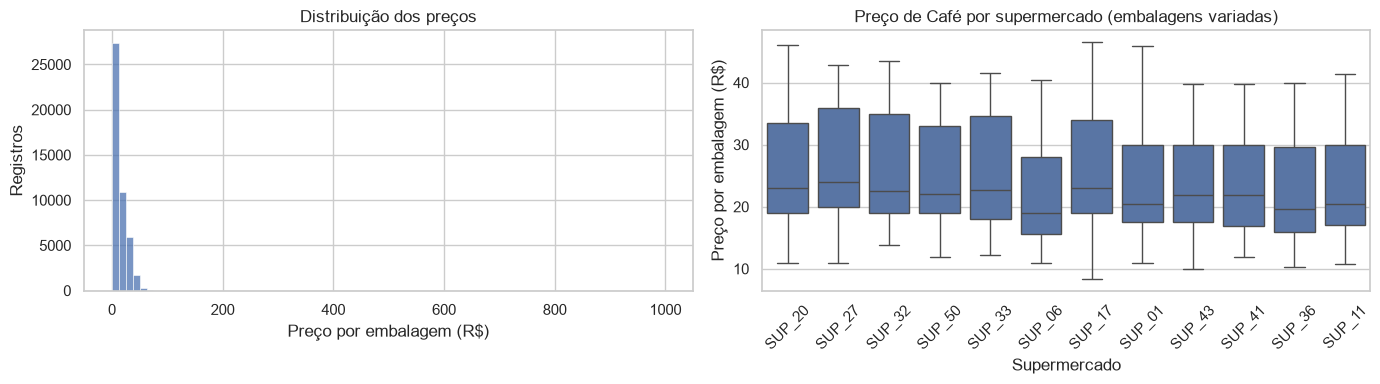

In [6]:
fig, axes=plt.subplots(1,2,figsize=(14,4))
sns.histplot(raw, x="Preco", bins=80, ax=axes[0]); axes[0].set(xlabel="Preço por embalagem (R$)",ylabel="Registros",title="Distribuição dos preços")
top=raw.Produto.value_counts().head(1).index[0]
sub=raw[raw.Produto.eq(top)].copy(); stores=sub.Estab.value_counts().head(12).index
sns.boxplot(data=sub[sub.Estab.isin(stores)], x="Estab", y="Preco", ax=axes[1],showfliers=False); axes[1].tick_params(axis="x",rotation=45); axes[1].set(title=f"Preço de {top} por supermercado (embalagens variadas)",xlabel="Supermercado",ylabel="Preço por embalagem (R$)")
plt.tight_layout(); plt.show()

## 6. Tendências e composição
As medianas agregadas misturam supermercados, marcas e quantidades de embalagem. Elas descrevem a composição da amostra ao longo do tempo. A distribuição de registros é exibida por produto.

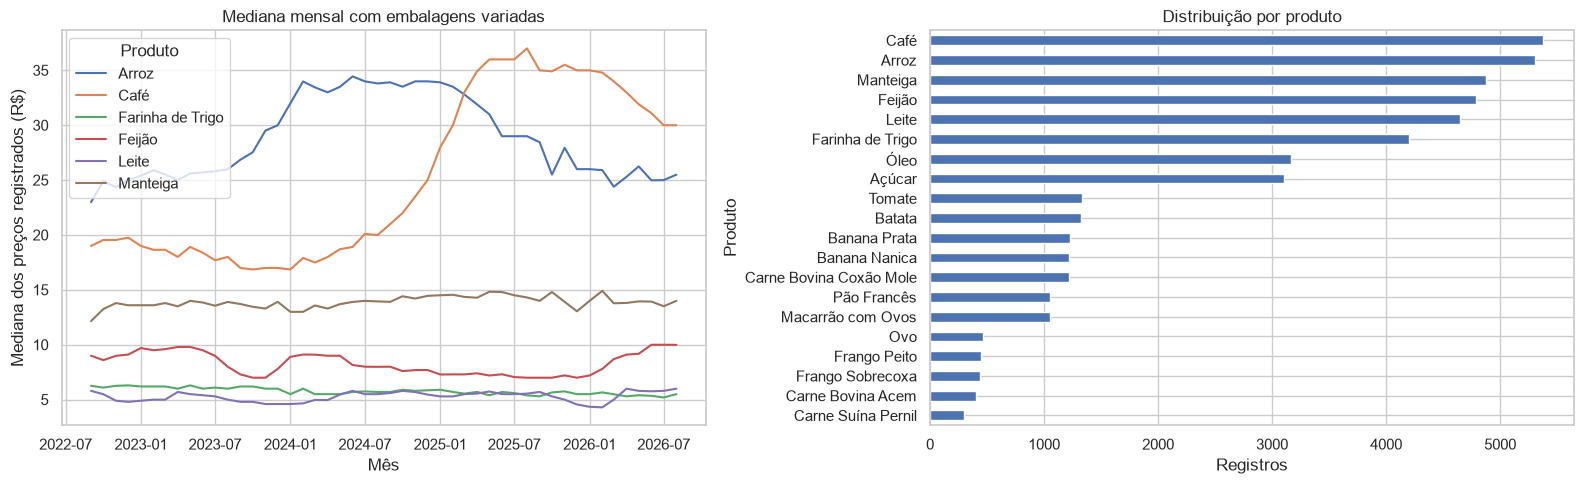

In [7]:
top_products=raw.Produto.value_counts().head(6).index
trend=raw[raw.Produto.isin(top_products)].groupby(["Mes_Ano_Data","Produto"],as_index=False).Preco.median()
fig, axes=plt.subplots(1,2,figsize=(16,5))
sns.lineplot(data=trend,x="Mes_Ano_Data",y="Preco",hue="Produto",ax=axes[0]); axes[0].set(title="Mediana mensal com embalagens variadas",xlabel="Mês",ylabel="Mediana dos preços registrados (R$)")
raw.Produto.value_counts().head(20).sort_values().plot.barh(ax=axes[1]); axes[1].set(title="Distribuição por produto",xlabel="Registros",ylabel="Produto")
plt.tight_layout(); plt.show()

### Evolução de embalagens comparáveis
Cada gráfico fixa supermercado, produto, marca informada e quantidade. Os pontos mostram medianas mensais e a linha é interrompida quando falta um mês. Os exemplos são as duas séries de produtos distintos com maior cobertura entre as séries de marca informada.

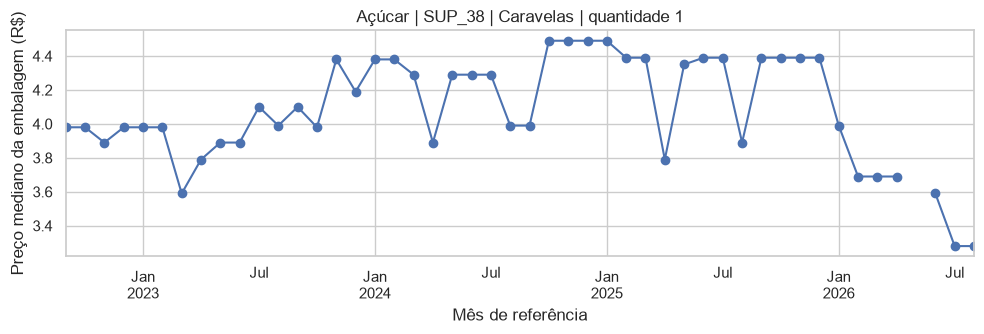

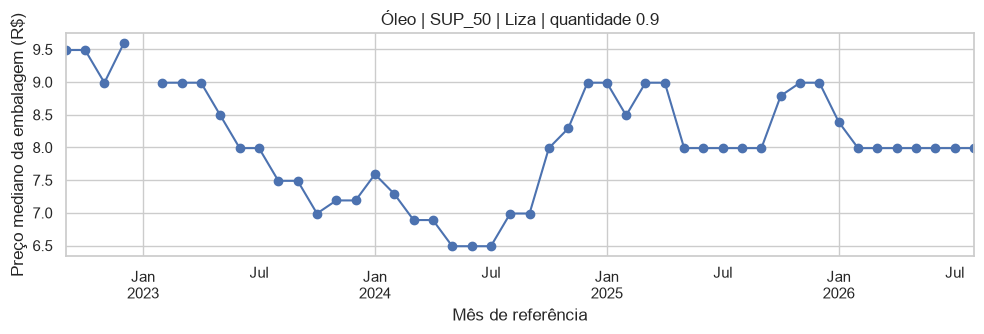

In [8]:
coverage = (
    monthly.loc[monthly.brand.ne(cleaning["missing_brand_label"])]
    .groupby(ENTITY, observed=True).size().rename("meses").reset_index()
    .sort_values("meses", ascending=False, kind="stable")
)
examples = coverage.drop_duplicates("product").head(2)
for key in examples[ENTITY].itertuples(index=False, name=None):
    mask = monthly[ENTITY].eq(pd.Series(key, index=ENTITY)).all(axis=1)
    prices = monthly.loc[mask].set_index("month").price_current.asfreq("MS")
    _, ax = plt.subplots(figsize=(10, 3.5))
    prices.plot(ax=ax, marker="o")
    store, product, brand, quantity = key
    ax.set(title=f"{product} | {store} | {brand} | quantidade {quantity:g}",
           xlabel="Mês de referência", ylabel="Preço mediano da embalagem (R$)")
    plt.tight_layout()
    plt.show()

## 7. Variações, volatilidade e disponibilidade
Mudanças são calculadas apenas entre meses consecutivos da mesma série. Valores extremos podem ser erros, promoções ou alterações reais e precisam de auditoria na origem. Volatilidade é o desvio padrão das variações mensais observadas.

Maiores variações absolutas — verificar, não excluir:


,supermarket,product,brand,quantity,month,price_current,change
15563,SUP_17,Frango Sobrecoxa,(não informada),1.0,2026-01-01,18.890,187.900000
40672,SUP_47,Pão Francês,(não informada),1.0,2025-11-01,17.990,178.900000
25611,SUP_32,Banana Nanica,(não informada),1.0,2024-10-01,504.995,49.550050
11082,SUP_13,Pernil,(não informada),1.0,2026-06-01,25.690,24.690000
38272,SUP_46,Batata,(não informada),1.0,2023-08-01,31.900,7.200514
24470,SUP_29,Feijão,Solito,1.0,2022-12-01,8.290,5.966387
26807,SUP_32,Pernil,(não informada),1.0,2026-08-01,28.900,4.463138
7141,SUP_11,Arroz,Tio João,5.0,2026-06-01,27.990,3.240909
27122,SUP_33,Arroz,Qualitá,5.0,2023-06-01,23.490,3.202147
27055,SUP_33,Arroz,Camil,5.0,2023-06-01,24.990,3.171953


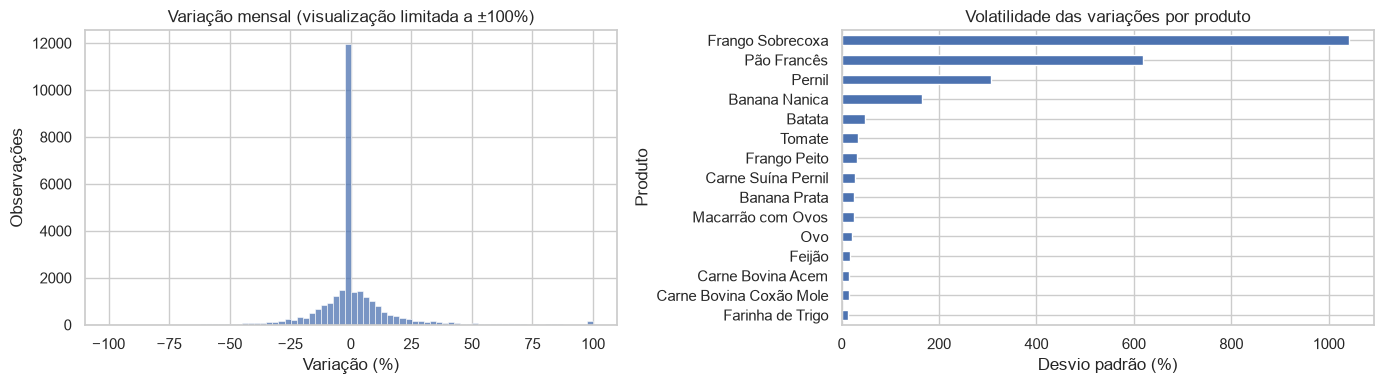

In [9]:
m=monthly.sort_values(ENTITY+["month"]).copy(); g=m.groupby(ENTITY,observed=True)
prev=g.price_current.shift(1); prev_month=g.month.shift(1)
consecutive=(m.month.dt.to_period("M").astype("int64")-prev_month.dt.to_period("M").astype("int64")).eq(1)
m["change"]= (m.price_current/prev-1).where(consecutive)
print("Maiores variações absolutas — verificar, não excluir:")
display(m.loc[m.change.abs().nlargest(15).index, ENTITY+["month","price_current","change"]])
fig,axes=plt.subplots(1,2,figsize=(14,4))
sns.histplot(m.change.dropna().clip(-1,1)*100,bins=80,ax=axes[0]); axes[0].set(title="Variação mensal (visualização limitada a ±100%)",xlabel="Variação (%)",ylabel="Observações")
vol=m.groupby("product").change.agg(["std","count"]).query("count >= 30").sort_values("std").tail(15)
vol["std"].mul(100).plot.barh(ax=axes[1]); axes[1].set(title="Volatilidade das variações por produto",xlabel="Desvio padrão (%)",ylabel="Produto")
plt.tight_layout(); plt.show()

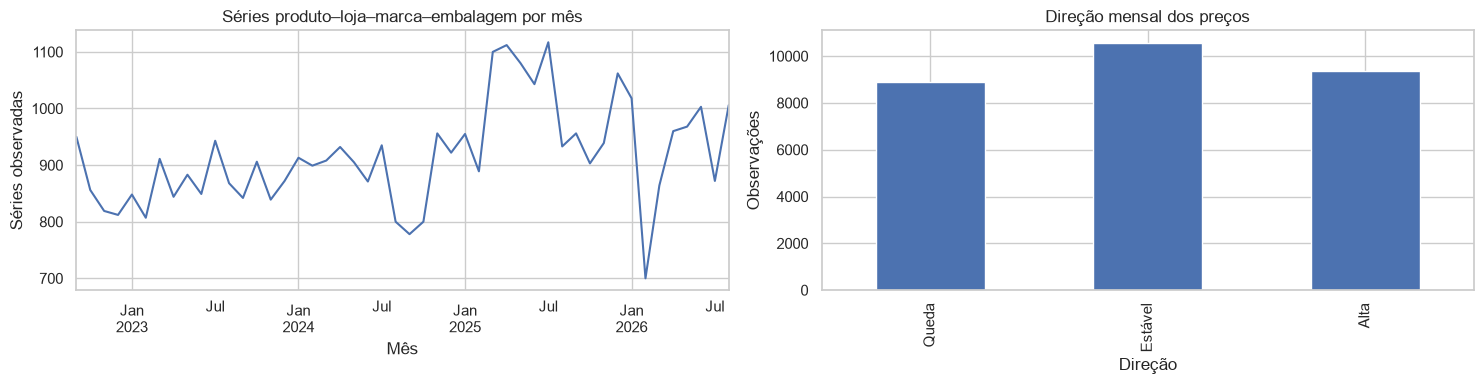

In [10]:
fig,axes=plt.subplots(1,2,figsize=(15,4))
availability=m.groupby("month").size(); availability.plot(ax=axes[0]); axes[0].set(title="Séries produto–loja–marca–embalagem por mês",xlabel="Mês",ylabel="Séries observadas")
direction=pd.cut(m.change,[-np.inf,-1e-12,1e-12,np.inf],labels=["Queda","Estável","Alta"]).value_counts().reindex(["Queda","Estável","Alta"])
direction.plot.bar(ax=axes[1]); axes[1].set(title="Direção mensal dos preços",xlabel="Direção",ylabel="Observações")
plt.tight_layout(); plt.show()

## 8. Distribuição inicial do alvo
O alvo usa o preço observado no mês calendário seguinte; sem ele não há rótulo. A amostra abaixo também exige dois meses prévios consecutivos.

In [11]:
supervised, feature_report=build_supervised(monthly)
display(pd.Series(feature_report,name="observações").to_frame())
display(supervised.target.value_counts().rename(index={0:"Sem alta >2%",1:"Alta >2%"}).to_frame("n"))
display(supervised.groupby(supervised.target_month.dt.to_period("M")).target.agg(["size","mean"]).rename(columns={"size":"n", "mean":"fração de altas"}).tail(12))

losses = pd.Series({
    "Sem preço no mês seguinte": feature_report["without_next_calendar_month"],
    "Com alvo, sem histórico consecutivo": feature_report["with_target_without_history"],
    "Exemplos elegíveis": feature_report["eligible"],
})
display(pd.DataFrame({"Observações mensais": losses, "Fração": losses / len(monthly)}))

,observações
monthly_observations,43948
without_next_calendar_month,15108
with_target,28840
with_target_without_history,11838
eligible,17002


,n
target,
Sem alta >2%,12045
Alta >2%,4957


,n,fração de altas
target_month,,
2025-09,406,0.256158
2025-10,346,0.349711
2025-11,313,0.306709
2025-12,372,0.233871
2026-01,388,0.257732
2026-02,230,0.330435
2026-03,157,0.375796
2026-04,146,0.301370
2026-05,120,0.325000


,Observações mensais,Fração
Sem preço no mês seguinte,15108,0.343770
"Com alvo, sem histórico consecutivo",11838,0.269364
Exemplos elegíveis,17002,0.386866


## 9. Conclusões exploratórias
A elegibilidade é afetada por marcas desconhecidas, séries interrompidas e pela exigência de histórico; observações elegíveis podem não representar todas as compras. Diferenças de embalagem, descrições e metodologia de coleta dificultam comparações. Os dados possuem meses e classes suficientes para uma avaliação supervisionada temporal, sem garantir estabilidade ou causalidade. Confira as contagens acima e os resultados independentes no notebook 3.

In [12]:
display(Markdown(f"Foram observados **{len(raw):,}** registros originais, **{cleaning['monthly_series']:,}** séries mensais distintas e **{len(supervised):,}** exemplos elegíveis; a fração de altas é **{supervised.target.mean():.1%}**."))

Foram observados **46,264** registros originais, **4,216** séries mensais distintas e **17,002** exemplos elegíveis; a fração de altas é **29.2%**.